In [4]:
from langgraph.graph import StateGraph , START, END
from typing import TypedDict, Literal


In [25]:
class QuadraticState(TypedDict):
    a: float
    b: float
    c: float

    eq : int
    discriminant : float
    result : float

In [26]:
def show_equation(state: QuadraticState )->QuadraticState:
    eq=f"{state['a']}X**2 + {state['b']}X + {state['c']}"
    return {'equation':eq}

In [27]:
def cal_discriminant(state: QuadraticState)->QuadraticState:
    discriminant= state["b"]**2 - (4*state["a"]* state["c"])
    return {'discriminant':discriminant}

In [28]:
def real_root(state:QuadraticState)->QuadraticState:
    root1= (-state["b"]+ (state["discriminant"]**0.5))/(2*state["a"])
    root2= (-state["b"]+ (state["discriminant"]**0.5))/(2*state["a"])
    result=f" {root1} and {root2}"
    return {"result":result}

In [ ]:
def repeated_root(state:QuadraticState)->QuadraticState:
    result= (-state["b"])/(2*state["a"])
    return {"result":result}

In [34]:
def no_root(state:QuadraticState):
    result= f"no real root"
    return {"result":result}

In [40]:
def conditional_root(state:QuadraticState)-> Literal["no_root","repeated_root","real_root"]:
    if state["discriminant"]>0:
        return "real_root"
    elif state["discriminant"]==0:
        return "repeated_root"
    else:
        return "no_root"

In [41]:
graph =StateGraph(QuadraticState)

graph.add_node("equation", show_equation)
graph.add_node("cal_discriminant", cal_discriminant)
graph.add_node("real_root", real_root)
graph.add_node("repeated_root",repeated_root)
graph.add_node("no_root",no_root)
graph.add_node("conditional_root", conditional_root)

graph.add_edge(START, "equation")
graph.add_edge("equation", "cal_discriminant")
graph.add_conditional_edges("cal_discriminant",conditional_root)
graph.add_edge("cal_discriminant", END)

workflow= graph.compile()


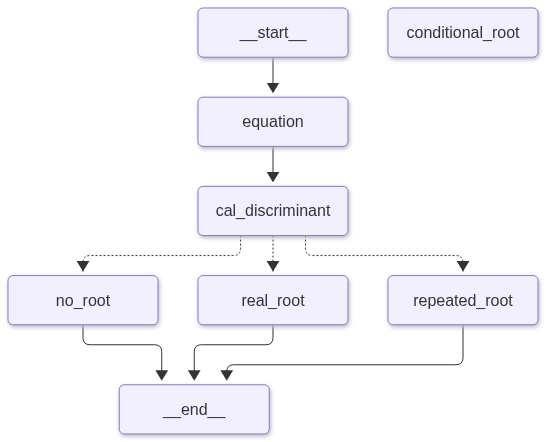

In [42]:
workflow

In [43]:
initial_state={
    'a':12,"b":5, "c":3
    }
final_state=workflow.invoke(initial_state)
print(final_state)

{'a': 12, 'b': 5, 'c': 3, 'discriminant': -119, 'result': 'no real root'}
